# CSS 布局

盒子模型（前端第05天，CSS第03天）


本篇接着上一天的继承性、层叠性，先解决“多条 CSS 同时控制一个元素，到底谁生效”，再学习如何通过内容、边框、内边距、外边距完成布局。

资料来自 `day05.rar` 中的 `day05（CSS03-盒子模型）v1.0.pdf`（50页）、课堂 HTML、`CSS第03天（盒子模型）总结.xmind`、必做与选做案例。按原课顺序整理，保留原图和代码；资料中的笔误、注释与当前代码状态的差异在对应位置说明。

本日要会做的事：计算选择器权重，用 Chrome 查找失效样式，用 PxCook 量取设计图，设置并计算盒子尺寸，区分两类外边距折叠，完成新浪导航和新闻列表。

代码用于阅读。课堂示例通常摘录 `<style>` 和 `<body>`；练习时放回对应 HTML 文件。综合作业保留完整 HTML，选做案例还需要与源码同级的 `images` 文件夹。


## 1. CSS 三大特性：优先级


### 1.1 不同选择器冲突时，先判断优先级

继承性让部分样式从父元素传给子元素；层叠性决定冲突样式如何覆盖。**同一个元素的同一个属性被多条规则直接设置时，还要比较优先级。**

本课的比较公式是：

`继承 < 通配符选择器 < 标签选择器 < 类选择器 < ID选择器 < 行内样式 < !important`

这里按课程中的普通页面样式比较。不能把这个口诀当成所有来源、所有复杂情况的完整 CSS 排序规则。

`!important` 写在属性值后、分号前，例如 `color: green !important;`。它作用于这条声明，不能把父元素上的重要性一起传给子元素。子元素已有直接设置的颜色时，不会因为父元素写了 `!important` 就放弃自己的颜色。原课不建议在日常开发中靠堆叠 `!important` 解决冲突。

在 `01-案例/01-优先级.html` 中，ID、类、标签、行内样式同时控制这个 `div`：

CSS（放在 `<style>` 内）：

```css
#box {
    color: orange;
}

.box {
    color: blue;
}

div {
    color: green !important;
}

body {
    color: red;
}

/* !important不要给继承的添加, 自己有样式无法继承父级样式 */
```

HTML（放在 `<body>` 内）：

```html
<!-- 意义: 当一个标签使用了多个选择器, 样式冲突的时候, 到底谁生效 -->
<div class="box" id="box" style="color: pink;">测试优先级</div>
```

当前文字应为**绿色**：`div` 的 `color` 带有 `!important`，覆盖普通行内粉色。去掉它，结果是行内的粉色；再去掉行内颜色，结果才是 ID 设置的橙色。`body` 的红色属于继承，不参与这几条直接声明的胜出比较。


### 1.2 复合选择器：计算权重元组

后代选择器等复合选择器不能只看“用了类还是标签”，要统计各级的数量。课程使用四位元组：

`(行内样式, ID选择器, 类选择器, 标签选择器)`

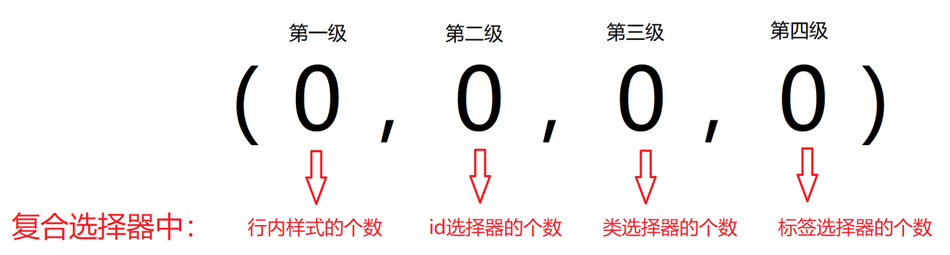

比较时从左往右，遇到第一处不同就能决定结果，后面的位不再看。**各级之间不进位**：再多的标签选择器也不会变成一个类选择器。同一元素、同一属性、重要性相同且四位完全相同时，再看书写顺序，后面的覆盖前面的。

补充：本课已学的 `:hover` 在权重中按类这一位计数；`*`、空格和 `>` 本身不增加权重。

`01-案例/02-权重叠加计算.html`：

CSS（放在 `<style>` 内）：

```css
/* #one {
  color: red;
}

.son {
  color: blue;
}

p {
  color: green;
} */

/* (行内, id, 类, 标签) */

/* (0, 1, 0, 1) */
 div #one {
  color: orange;
}

/* (0, 0, 2, 0) */
.father .son {
  color: skyblue;
}

/* 0, 0, 1, 1 */
.father p {
  color: purple;
}

/* 0, 0, 0, 2 */
div p {
  color: pink;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="father">
  <p class="son" id="one">我是一个标签</p>
</div>
```

这些启用的规则都直接选中了 `p`：

| 选择器 | 权重 | 颜色 |
| --- | --- | --- |
| `div #one` | `(0, 1, 0, 1)` | `orange`，胜出 |
| `.father .son` | `(0, 0, 2, 0)` | `skyblue` |
| `.father p` | `(0, 0, 1, 1)` | `purple` |
| `div p` | `(0, 0, 0, 2)` | `pink` |

第一位都为0，第二位只有 `div #one` 为1，直接确定文字为橙色。文件开头单独的 `#one`、`.son`、`p` 三条规则已被注释，不参与当前结果。


### 1.3 权重题的解题顺序

1. 找到题目真正询问的元素。
2. 判断哪些选择器直接匹配它。只匹配祖先的规则先归为继承来源。
3. 对直接声明先检查 `!important`，再比较权重。
4. 权重相同再比较书写顺序。
5. 如果该元素没有自己的颜色，沿父子关系看它继承到的最终颜色。

原课提醒：选择元素应尽量精准，避免无必要地让多条规则同时控制一个标签。


### 1.4 权重计算题：第1题

文件：`01-案例/03-（案例）权重叠加计算题/第1题.html`。判断 `p#son.c2` 的文字颜色。

CSS（放在 `<style>` 内）：

```css
/* (行内, id, 类, 标签) */
/* !important 最高 */
/* 继承: 最低 */

/* (0, 2, 0, 0) */
#father #son {
	color:blue; 
} 

/* (0, 1, 1, 1) */
#father p.c2 {
	color:black;
} 

/* (0, 0, 2, 2) */
div.c1 p.c2 {
	color:red;
} 

/* 继承, 最低 */
#father { 
	color:green !important;
} 

/* 继承, 最低 */
div#father.c1 {
	color: yellow ;
}
```

HTML（放在 `<body>` 内）：

```html
<div id="father" class="c1">
	<p id="son" class="c2">
		这行文本是什么颜色的？ 
	</p>
</div>
```

直接匹配 `p` 的前三条权重分别为 `(0, 2, 0, 0)`、`(0, 1, 1, 1)`、`(0, 0, 2, 2)`，因此结果为**蓝色**。

`#father` 和 `div#father.c1` 选中的是父 `div`，对题目中的 `p` 只可能提供继承颜色。父元素最终为绿色，也不能压过 `p` 上直接设置的蓝色；父元素声明里的 `!important` 不改变这一点。


### 1.5 权重计算题：第2题和第3题

**第2题：标签选择器选中一类元素。** 文件：`01-案例/03-（案例）权重叠加计算题/第2题.html`。

CSS（放在 `<style>` 内）：

```css
	/* (行内, id, 类, 标签) */
	/* !important 最高 */
	/* 继承: 最低 */

	/* 2 */
  div div {
		color: skyblue;
	} 

	/* 1 */
	div {
		color: red;
	}
```

HTML（放在 `<body>` 内）：

```html
<div>
	<div>
		<div>
			这行文本是什么颜色？
		</div>
	</div>
</div>
```

最内层 `div` 同时直接匹配 `div div` 和 `div`。前者为 `(0, 0, 0, 2)`，后者为 `(0, 0, 0, 1)`，结果为**天蓝色**。不能把 `div` 设置的红色误判为只属于外层的继承样式。

**第3题：权重的各位不存在进位。** 文件：`01-案例/03-（案例）权重叠加计算题/第3题.html`。

CSS（放在 `<style>` 内）：

```css
/* (行内, id, 类, 标签) */
div div div div div div div div div div div div {  
	color: red;
}

.one { 
	color: pink;
}
```

HTML（放在 `<body>` 内）：

```html
<div>
	<div>
		<div>
			<div>
				<div>
					<div>
						<div>
							<div>
								<div>
									<div>
										<div>
											<div class="one">这行文字是什么颜色的？</div>
										</div>
									</div>
								</div>
							</div>
						</div>
					</div>
				</div>
			</div>
		</div>
	</div>
</div>
```

长选择器含12个 `div`，权重为 `(0, 0, 0, 12)`；`.one` 为 `(0, 0, 1, 0)`。比较第三位时类选择器已胜出，所以最内层文字为**粉色**。不要把元组当成十进制数相加。


### 1.6 权重计算题：第4题和第5题

**第4题：权重相同，再看层叠。** 文件：`01-案例/03-（案例）权重叠加计算题/第4题.html`。

CSS（放在 `<style>` 内）：

```css
/* (0, 0, 2, 1) */
.c1 .c2 div { 
	color: blue;
}

/* (0, 1, 0, 1) */
div #box3 {
	color:green;
}

/* (0, 1, 0, 1) */
#box1 div {
	color:yellow;
}
```

HTML（放在 `<body>` 内）：

```html
<div id="box1" class="c1">
	<div id="box2" class="c2">
		<div id="box3" class="c3">
			这行文本是什么颜色的？
		</div>
	</div>
</div>
```

对最内层 `#box3`，`.c1 .c2 div` 为 `(0, 0, 2, 1)`；`div #box3` 和 `#box1 div` 都为 `(0, 1, 0, 1)`。后两条更高且相同，最后写的黄色胜出，结果为**黄色**。

**第5题：目标元素的颜色全部来自继承。** 文件：`01-案例/03-（案例）权重叠加计算题/第5题.html`。

CSS（放在 `<style>` 内）：

```css
/* 都是继承, 继承里面谁高, 看继承哪个父级, 哪个父级高, 哪个选择器生效 */

/* 继承 */
div p {
	color:red;
} 

/* 继承 */
.father {
	color:blue;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="father">
	<p class="son"> 
		<span>文字</span>
	</p>
</div>
```

`span` 没有自己的颜色，结果为**红色**。判断路径是：`.father` 直接把外层 `div` 设为蓝色；`div p` 直接把 `p` 设为红色；`span` 再继承父元素 `p` 的最终颜色。

原代码注释把这个过程描述为比较各祖先的权重，容易误解。补充说明：**不能跨不同元素比较祖先选择器的权重来决定继承色**。这里先计算每个元素自己的颜色，再由子元素继承父元素的结果；不是 `.father` 的类权重和 `div p` 的标签权重竞争。


### 1.7 Chrome 调试工具：样式不出来时怎样查错

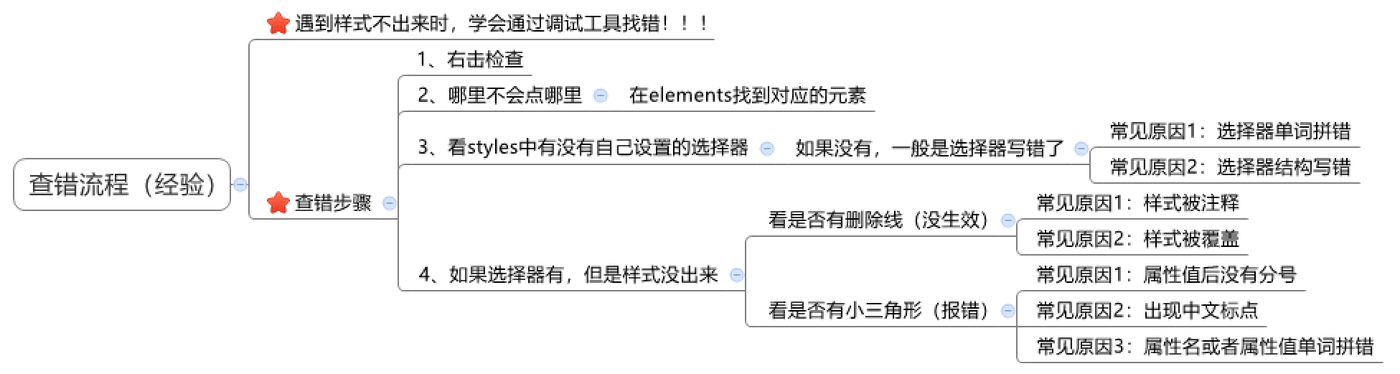

1. 在网页上右击目标位置，选择“检查”，在 `Elements` 中确认选中了正确元素。
2. 查看 `Styles` 中有没有自己写的选择器。没有时先核对选择器拼写，再核对 HTML 层级、类名与选择器结构。
3. 选择器出现了但效果没有出现时，查看声明是否被划掉。检查是不是自己取消勾选、注释掉了声明，或被另一条样式覆盖；有冲突时按优先级判断。
4. 有警告标记时，检查属性名、属性值、英文标点和声明之间的分号。也检查附近是否存在语法问题，不能只盯着当前一行。
5. 在调试工具中尝试修改，确认效果后，把修改保存到源 HTML/CSS 文件，再刷新验证。

补充：最后一条声明的末尾分号可以省略；声明之间漏掉分号却会让解析出错。本课强调写全分号，是为了避免把后一条声明连进前一条。

资料目录 `01-案例/04-（操作）Chrome调试工具查错流程` 有6个文件，均使用 `.father .son .sun` 的三级嵌套。保存下来的文件有些已经是修正后的状态：

| 文件 | 当前源码状态与预期 |
| --- | --- |
| `demo1.html` | 选择器有效，`color: blue;`，文字蓝色 |
| `demo2.html` | 选择器有效，`color: red;`，文字红色 |
| `demo3.html` | 多余的 `}` 已在注释中，当前颜色橙色 |
| `demo4.html` | `color: red;`、`font-size: 20px;` 都有效 |
| `demo5.html` | 同样是红色、20px；`color:red` 中没有空格也合法 |
| `demo6.html` | `redd` 不是合法颜色，颜色声明失效，字号20px仍有效 |

`demo3.html` 保留了“上一行出错，下一行会受影响”的检查提醒。当前 `/* } */` 是注释，不能当作一个正在生效的错误：

```css
/* 上一行出错, 下一行会受影响 */
/* } */

.father .son .sun {
  color: orange;
}
```

`demo6.html` 中的拼写错误仍然存在：

CSS（放在 `<style>` 内）：

```css
.father .son .sun {
  color: redd;
  font-size: 20px;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="father">
  <div class="son">
    <div class="sun">孙子</div>
  </div>
</div>
```

打开 `demo6.html`，选中 `.sun`，应能找到这条规则并看到无效的颜色值；把 `redd` 改成 `red`，文字才变红。这个例子也说明：同一规则的一条声明失效，不等于整条规则里的字号也失效。


## 2. PxCook 的基本使用

布局前先从设计图取得尺寸、颜色。本课使用 PxCook 测量，避免凭感觉填数值。


### 2.1 打开并查看设计图

1. 打开软件。
2. 把设计图拖入软件，新建项目。
3. 放大后查看边界、文字与间距，用量尺寸工具取得宽、高及间隔，用吸色工具取得颜色。

| 操作 | 原课快捷键 |
| --- | --- |
| 放大设计图 | `Ctrl` + `+` |
| 缩小设计图 | `Ctrl` + `-` |
| 移动设计图 | 按住空格，鼠标拖动 |


### 2.2 从 PSD 获取数据

如果拿到的是 PSD 设计文件，可切换到开发界面，点击对应元素获取数据。本日提供的案例设计图为 PNG，练习时使用测量、吸色功能；不能把 PNG 当作可点击读取图层参数的 PSD。

测量结果随后写进案例 HTML 的 `<style>`。在浏览器中对照设计图，细小误差可用 Chrome 调试工具调整；调试成功后保存源码。


## 3. 盒子模型


### 3.1 四个组成部分

浏览器渲染页面时，可以把每个元素看成一个矩形盒子。盒子从内到外由四部分组成：

1. 内容区域 `content`：文字、图片等实际内容。
2. 内边距 `padding`：内容与边框之间的距离。
3. 边框 `border`：盒子的线条。
4. 外边距 `margin`：边框外、盒子与盒子之间的距离。

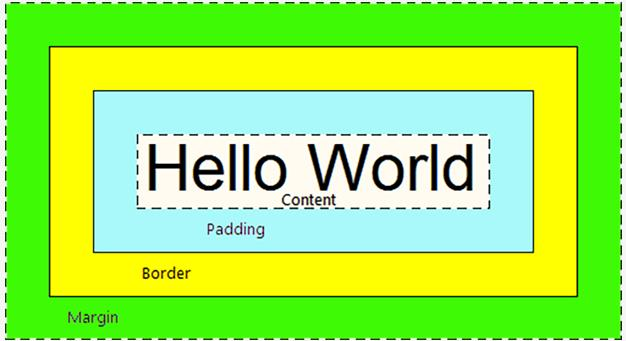

课程用现实包装盒帮助记忆：电脑是内容，填充物是内边距，纸箱边缘是边框，纸箱与纸箱之间是外边距。

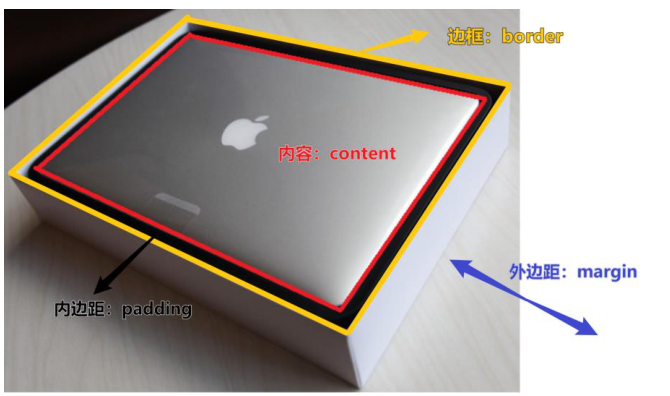

补充：`margin` 区域本身透明，不会绘制这个元素的背景；背景色可以覆盖内容和内边距。后面的尺寸计算把“盒子实际大小”明确为边框盒，即 `content + padding + border`，不包含外边距。

课堂 `05-体验盒子模型.html` 用两个盒子同时展示四部分：

CSS（放在 `<style>` 内）：

```css
/* 纸箱子, 填充泡沫 */
div {
    width: 300px;
    height: 300px;
    background-color: pink;
    /* 边框线 == 纸箱子 */
    border: 1px solid #000;
    /* 内边距 == 填充泡沫 : 出现在内容和盒子边缘之间 */
    padding: 20px;

    /* 外边距 : 出现在两个盒子之间, 出现在盒子的外面*/
    margin: 50px;
}
```

HTML（放在 `<body>` 内）：

```html
<div>内容电脑</div>
<div>内容电脑</div>
```

每个盒子的内容区为 `300×300`，四周 `1px` 边框和 `20px` 内边距使边框盒成为 `342×342`。四周 `50px` 外边距提供外部间隔；它不会把边框盒变成 `442×442`，两个盒子的垂直间隔还要按后面讲的外边距合并判断。


### 3.2 内容区域的宽高

`width` 和 `height` 默认设置的是**内容区域**的宽和高，不包含 `padding`、`border`、`margin`。

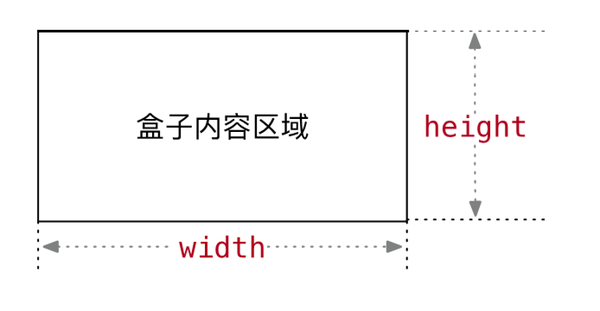

CSS（放在 `<style>` 内）：

```css
div {
    width: 200px;
    height: 200px;
    background-color: pink;
}
```

HTML（放在 `<body>` 内）：

```html
<div>文字</div>
```

上例的粉色内容区是 `200px × 200px`。在浏览器检查元素时，可以在盒模型图中分开查看内容、内边距、边框和外边距，避免把所有数值都理解成 `width`。


### 3.3 边框：粗细、样式、颜色

边框至少要有可见的样式。三个单项属性分别是 `border-width`、`border-style`、`border-color`；常用样式为 `solid` 实线、`dashed` 虚线、`dotted` 点线。

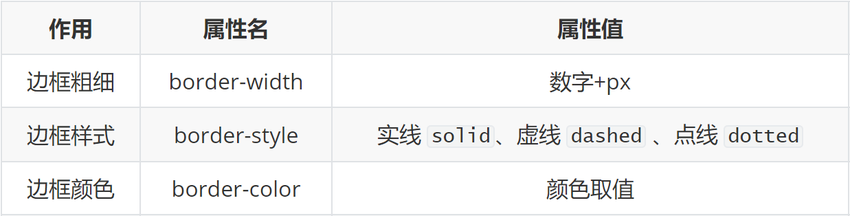

推荐用连写：`border: 宽度 样式 颜色;`，三者顺序不影响浏览器识别。例如 `border: 1px solid red;`。在编辑器输入 `bd` 后按 `Tab`，可用 Emmet 生成边框模板。

只改一个方向时，使用 `border-top`、`border-right`、`border-bottom` 或 `border-left`，值仍然是连写形式。

CSS（放在 `<style>` 内）：

```css
div {
    width: 200px;
    height: 200px;
    background-color: pink;
    /* border: 粗细  线条样式   颜色 -- 不分先后顺序 */
    /* solid : 实线 */
    /* border: 1px solid #000; */

    /* dashed: 虚线 */
    /* border: 5px dashed #000; */

    /* dotted : 点线 */
    /* border: 5px dotted #000; */

    border-left: 5px dotted #000;
    border-right: 5px dotted #000;
    border-top: 1px solid red;
    border-bottom: 1px solid red;
}
```

HTML（放在 `<body>` 内）：

```html
<div>内容</div>
```

`07-盒子模型-边框.html` 当前左右是 `5px dotted #000`，上下是 `1px solid red`。内容区 `200×200`，所以边框盒宽 `210px`、高 `202px`。文件中前面的整圈边框示例保持注释，便于逐个启用并对照三种边框样式。

原课的两道写法练习：四周20px蓝色实线写 `border: 20px solid blue;`；仅上边框10px黄色虚线写 `border-top: 10px dashed yellow;`。


### 3.4 只设置边框时，怎样满足设计稿尺寸

初级计算公式：

```text
盒子宽度 = 左边框 + 内容宽度 + 右边框
盒子高度 = 上边框 + 内容高度 + 下边框
```

需求是边框盒 `400×400`、背景绿色、四周 `10px` 黑色实线时，内容宽高应手动内减为 `380×380`：

CSS（放在 `<style>` 内）：

```css
div {
    /* border 撑大盒子尺寸 */
    /* 盒子尺寸 = width  / height + 边框线 */
    /* 如果400 * 400 尺寸 */
    width: 380px;
    height: 380px;
    background-color: green;
    border: 10px solid #000;
}
```

HTML（放在 `<body>` 内）：

```html
<div>div</div>
```

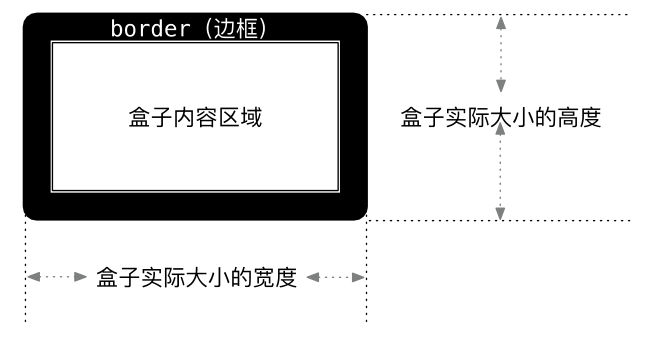

同样，`09-盒子模型-案例.html` 用 `280×280` 的粉色内容区加四周 `10px` 蓝色边框，得到 `300×300` 的边框盒：

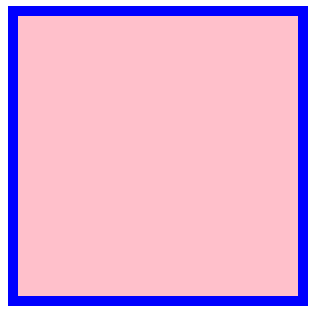

CSS（放在 `<style>` 内）：

```css
div {
    width: 280px;
    height: 280px;
    background-color: #ffc0cb;
    border: 10px solid #00f;
}
```

HTML（放在 `<body>` 内）：

```html
<div></div>
```


### 3.5 新浪导航：先做出固定宽度版本

课堂文件 `01-案例/10-综合案例-新浪导航.html` 演示了布局顺序：外层 `.box` 只有高度和上下边框；每个 `a` 转为行内块，设置宽高、文字居中、行高、字号、颜色和去下划线；`:hover` 再修改背景和文字颜色。

CSS（放在 `<style>` 内）：

```css
.box {
    height: 40px;
    border-top: 3px solid #ff8500;
    border-bottom: 1px solid #edeef0;
}

/* 后代: box里面的a */
.box a {
    width: 80px;
    height: 40px;
    /* 推荐先加上: 清楚的看到文字在什么位置 */
    /* background-color: #edeef0; */
    display: inline-block;
    text-align: center;
    line-height: 40px;
    font-size: 12px;
    color: #4c4c4c;
    text-decoration: none;
}

.box a:hover {
    background-color: #edeef0;
    color: #ff8400;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">
    <a href="#">新浪导航</a>
    <a href="#">新浪导航</a>
    <a href="#">新浪导航</a>
    <a href="#">新浪导航</a>
</div>
<p>
    <a href="#"></a>
</p>
```

课堂文件保留了锚点之间的换行空白和一个空的 `p`，适合观察原始课堂步骤。上面代码的外层边框盒高度是 `40 + 3 + 1 = 44px`；链接宽 `80px`、高 `40px`，外层没有固定宽度，会占满父级可用行宽。

原课布局顺序是：从外往内、从上往下。每个盒子先写宽高，再加辅助背景颜色看清位置，随后设置 `border / padding / margin`，最后调整 `color / font- / text-` 等细节。正常文字 `#4c4c4c`、字号12px；悬停时背景 `#edeef0`、文字 `#ff8400`。在浏览器分别查看正常和悬停状态，单行文字应通过 `line-height: 40px` 在40px高的链接内垂直居中。

作业要求的完整版本会清除默认内外边距，并把相邻锚点写在同一行，避免 HTML 空白产生行内块间隙：

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    /* 清除标签默认的margin和padding */
    * {
      margin: 0;
      padding: 0;
    }

    .box {
      /* 不设置宽度，块级元素默认会占满一行 */
      height: 40px;
      /* background-color: skyblue; */
      border-top: 3px solid #ff8500;
      border-bottom: 1px solid #edeef0;
    }

    .box a {
      /* 转换行内块 */
      display: inline-block;
      width: 80px;
      height: 40px;
      /* background-color: pink; */
      color: #4c4c4c;
      text-decoration: none;
      text-align: center;
      line-height: 40px;
      font-size: 12px;
    }

    .box a:hover {
      background-color: #edeef0;
      color: #ff8400;
    }
  </style>
</head>
<body>
  <div class="box">
    <a href="#">新浪导航</a><a href="#">新浪导航</a><a href="#">新浪导航</a><a href="#">新浪导航</a>
  </div>
</body>
</html>
```

配套设计图：

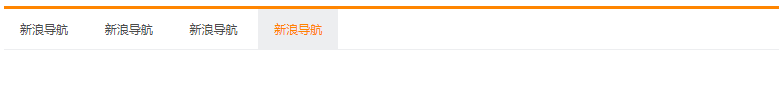


### 3.6 内边距：内容与边框之间的距离

`padding` 控制内容与边框的间距。复合写法最多四个值，按照“从上开始，顺时针一圈”分配：

| 写法 | 含义 |
| --- | --- |
| `padding: 10px;` | 上右下左都是 `10px` |
| `padding: 10px 20px;` | 上下 `10px`，左右 `20px` |
| `padding: 10px 20px 30px;` | 上 `10px`，左右 `20px`，下 `30px` |
| `padding: 10px 20px 30px 40px;` | 上、右、下、左依次设置 |

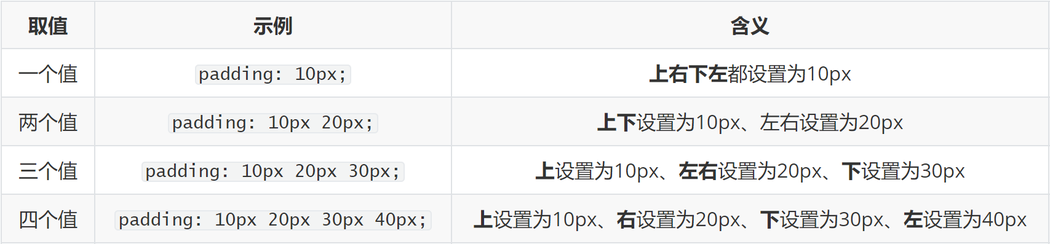

只设置一个方向可写 `padding-top`、`padding-right`、`padding-bottom` 或 `padding-left`。

CSS（放在 `<style>` 内）：

```css
div {
    width: 300px;
    height: 300px;
    background-color: pink;
    /* 添加了4个方向的内边距 */
    /* padding: 50px; */

    /* padding 属性可以当做复合属性使用, 表示单独设置某个方向的内边距 */
    /* padding 最多取4个值 */

    /* 四值: 上  右   下  左 */
    /* padding: 10px 20px 40px 80px; */

    /* 三值 : 上   左右   下*/
    /* padding: 10px 40px 80px; */

    /* 两值 : 上下  左右*/
    /* padding: 10px 80px; */

    padding-left: 10px;
    padding-bottom: 50px;
}

/* 多值写法, 永远都是从上开始顺时针转一圈, 如果数不够, 看对面 */
```

HTML（放在 `<body>` 内）：

```html
<div>文字</div>
```

当前启用 `padding-left: 10px` 和 `padding-bottom: 50px`，因此内容盒 `300×300` 会变成边框盒 `310×350`（没有设置边框）。文件中四值、三值、两值和四方向示例保留为注释，便于逐个取消注释观察。


### 3.7 边框和内边距一起计算

终极计算公式：

```text
盒子宽度 = 左边框 + 左 padding + 内容宽度 + 右 padding + 右边框
盒子高度 = 上边框 + 上 padding + 内容高度 + 下 padding + 下边框
```

讲义这一页把高度公式的“内容宽度”写成了笔误，计算高度时应使用**内容高度**。

CSS（放在 `<style>` 内）：

```css
div {
    /* 撑大盒子的都有啥? border + padding */
    width: 240px;
    height: 240px;
    background-color: pink;
    border: 10px solid #000;
    padding: 20px;
}
```

HTML（放在 `<body>` 内）：

```html
<div>文字</div>
```

`12-盒子模型-内边距-尺寸.html` 的内容为 `240×240`，四周 `10px` 边框、`20px` 内边距，边框盒为 `300×300`。需要固定外框为 `300×300` 时，就要按公式把内容尺寸手动减小。

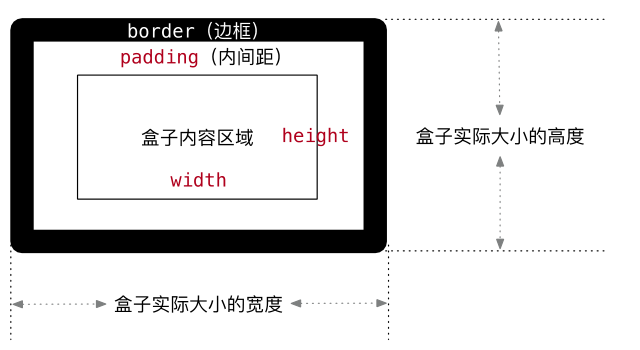


### 3.8 新浪导航优化：让宽度跟随文字

固定 `width: 80px` 时，导航文字变长就容易放不下。优化版本删除固定宽度，改用左右 `padding: 0 16px`，于是每个链接的边框盒宽度等于“文字宽度 + 32px”。

CSS（放在 `<style>` 内）：

```css
.box {
    height: 40px;
    border-top: 3px solid #ff8500;
    border-bottom: 1px solid #edeef0;
}

/* 后代: box里面的a */
.box a {
    padding: 0 16px;
    /* width: 80px; */
    height: 40px;
    /* 推荐先加上: 清楚的看到文字在什么位置 */
    /* background-color: #edeef0; */
    display: inline-block;
    text-align: center;
    line-height: 40px;
    font-size: 12px;
    color: #4c4c4c;
    text-decoration: none;
}

.box a:hover {
    background-color: #edeef0;
    color: #ff8400;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">
    <a href="#">新浪</a>
    <a href="#">新浪导航新浪导航</a>
    <a href="#">新浪导航</a>
    <a href="#">新浪导航</a>
</div>
<p>
    <a href="#"></a>
</p>
```

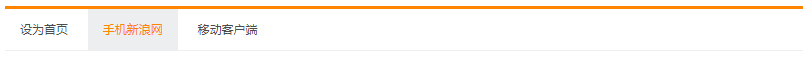

课堂文件保留原来的空白 `p` 和默认间距，目的是展示课堂过程；作业完整版本可以继续沿用前面统一清除默认间距的做法。块级元素在未设置 `width` 时，通常会占满父级可用宽度；这时增加左右 `padding` 或 `border` 不会把它再撑出父级宽度，浏览器会让内容区域收缩来适配。

补充：讲义称“默认是父盒子的宽度”，准确理解是普通流块级元素的 `width: auto` 会适配父级可用宽度，并非继承父元素的 `width`。这个特例讨论自动宽度；已经明确设置内容 `width` 的盒子仍按前面的内容盒公式加边框和内边距。优化效果图使用“设为首页、手机新浪网、移动客户端”，课堂代码用不同长度的“新浪”作演示，两者都说明左右留白固定、宽度随文字变化。


### 3.9 CSS3 盒模型：自动内减

手动内减需要每次计算内容宽高。设置：

```css
box-sizing: border-box;
```

就把 `width`、`height` 解释为边框盒尺寸，浏览器自动从内容区域中扣除 `padding` 和 `border`。

CSS（放在 `<style>` 内）：

```css
div {
    width: 100px;
    height: 100px;
    background-color: pink;
    border: 10px solid #000;
    padding: 20px;

    /* 內减模式 */
    /* 变成CSS3的盒子模型, 好处: 加了border和padding不需要手动减法 */
    box-sizing: border-box;
}
```

HTML（放在 `<body>` 内）：

```html
<div>文字</div>
```

本课堂文件设置 `width: 100px; height: 100px; border: 10px; padding: 20px;`，启用 `border-box` 后外框仍是 `100×100`，内容区域为 `40×40`。讲义的 `300×300` 练习同理：四周边框 `10px`、内边距 `20px` 时，内容为 `240×240`。


## 4. 外边距：间隔、居中与折叠


### 4.1 外边距的写法和单方向作用

`margin` 设置边框外、盒子与盒子之间的距离，复合写法与 `padding` 完全同样遵循上、右、下、左的顺序。

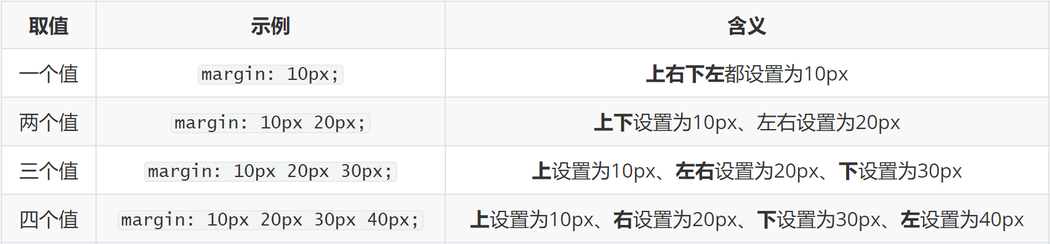

CSS（放在 `<style>` 内）：

```css
div {
    width: 100px;
    height: 100px;
    background-color: pink;
    margin: 50px;
    margin-left: 100px;
}
```

HTML（放在 `<body>` 内）：

```html
<div>div</div>
```

这里四周先设置 `50px`，再用 `margin-left: 100px` 覆盖左侧，所以当前盒子边框盒仍是 `100×100`，外部间距是上/右/下 `50px`、左 `100px`。

单方向应用：`margin-left` 让当前盒子向右移动；`margin-right` 推动后面的盒子向右；`margin-top` 让当前盒子向下；`margin-bottom` 让下面的盒子向下。普通水平流中左右外边距相加，垂直普通块级流中上下外边距可能折叠，不能把这些描述套到所有布局模式。

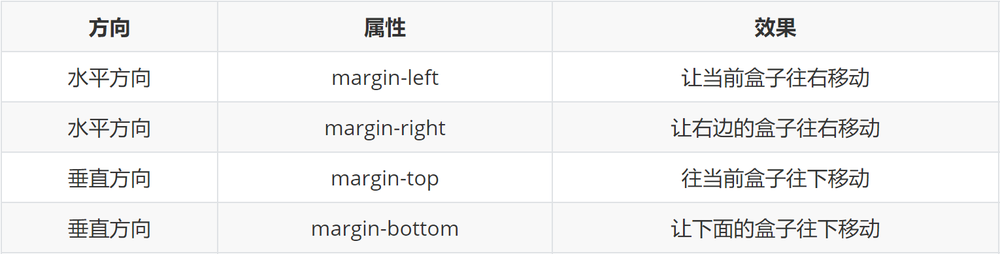


### 4.2 清除浏览器默认内外边距

浏览器会给 `body`、`p`、标题、列表等标签设置默认间距，例如 `body` 常见默认 `margin: 8px`，`p` 有上下外边距，`ul` 有上下外边距和 `padding-left`。项目开始时通常统一清除，再按设计图重新设置：

CSS（放在 `<style>` 内）：

```css
* {
    margin: 0;
    padding: 0;
}
```

HTML（放在 `<body>` 内）：

```html
<p>pppp</p>
<p>pppp</p>
<h1>h1</h1>
<ul>
    <li>lili</li>
</ul>
```

清除列表的 `margin` 和 `padding` 不会自动移除项目符号；需要隐藏符号时另写 `list-style: none;`，新闻列表案例会用到。

课堂还给出淘宝、京东样式重置的浏览器截图，说明不同网站会选择不同的标签集合：

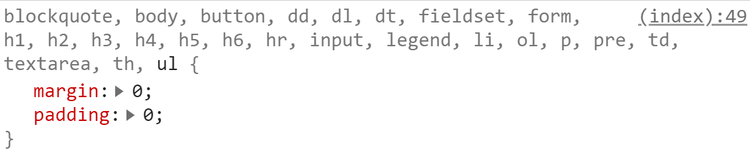

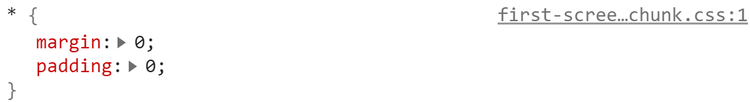


### 4.3 版心居中

固定宽度的网页有效内容区域常称为“版心”。块级盒子在父级中水平居中使用：

CSS（放在 `<style>` 内）：

```css
div {
    width: 1000px;
    height: 300px;
    background-color: pink;
    margin: 0 auto;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 版心: 网页的有效内容 -->
<!-- 版心居中 -->
<div>版心</div>
```

`margin: 0 auto` 的前提是盒子有明确宽度，并且左右仍有可分配空间。它让盒子水平居中，不会让文字在盒内居中；文字需要另写 `text-align: center`。


### 4.4 网页新闻列表：从外到内完成案例

作业目录 `04-作业/01-综合案例（必做）/02-（案例）综合案例2-网页新闻列表案例` 给出设计图、文本和要求。完整源码：

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    /* 清除标签默认的margin和padding */
    * {
      margin: 0;
      padding: 0; 
    }

    body {
      /* 去除行高带来的默认间隙，完成精准布局 */
      line-height: 1;
    }

    .box {
      width: 500px;
      height: 400px;
      /* background-color: pink; */
      border: 1px solid #ccc;
      padding: 41px 30px 0;
      /* 自动内减 */
      box-sizing: border-box;
    }

    .box h2 {
      height: 41px;
      /* background-color: pink; */
      border-bottom: 1px solid #ccc;
      /* 自动内减 */
      box-sizing: border-box;
      font-size: 30px;
    }

    .box ul {
      list-style: none;
    }

    .box ul li {
      height: 50px;
      padding-left: 30px;
      border-bottom: 1px dashed #ccc;
      line-height: 50px;
    }

    .box li a {
      text-decoration: none;
      font-size: 18px;
      color: #666;
    }

  </style>
</head>
<body>
  <div class="box">
    <h2>最新文章/New Articles</h2>
    <ul>
      <li><a href="#">北京招聘网页设计，平面设计，php</a></li>
      <li><a href="#">体验javascript的魅力</a></li>
      <li><a href="#">jquery世界来临</a></li>
      <li><a href="#">网页设计师的梦想</a></li>
      <li><a href="#">jquery中的链式编程是什么</a></li>
    </ul>
  </div>
</body>
</html>
```

布局尺寸的关键点：`.box` 的边框盒为 `500×400`，`box-sizing: border-box` 后四周 `1px` 边框、顶部 `41px` 内边距、左右各 `30px` 内边距都包含在这个尺寸内；内部可用内容宽度为 `500 - 2 - 60 = 438px`，内容高度为 `400 - 2 - 41 = 357px`。`h2` 用 `height: 41px` 和 `box-sizing: border-box` 包含下边框；`li` 没有单独设置 `box-sizing`，它的 `height: 50px` 是内容高度，再加下方 `1px` 虚线。

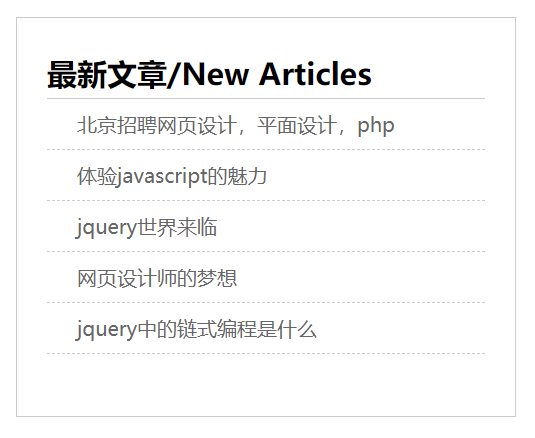

课堂另一个版本 `01-案例/18-综合案例-新闻列表.html` 使用全局 `box-sizing: border-box`、`.news` 的 `padding: 42px 30px 0`、`h2` 的 `line-height: 1` 加 `padding-bottom: 9px`，并让五条列表使用相同文本。它是同一布局思路的课堂变体，不能和必做源码的尺寸逐项混写：

CSS（放在 `<style>` 内）：

```css
* {
    margin: 0;
    padding: 0;
    /* 所有的标签都可能添加内边距或border, 都內减模式 */
    box-sizing: border-box;
}

.news {
    width: 500px;
    height: 400px;
    border: 1px solid #ccc;
    margin: 50px auto;
    padding: 42px 30px 0;
}

.news h2 {
    border-bottom: 1px solid #ccc;
    font-size: 30px;

    /* 行高是1倍, 就是字号的大小 */
    line-height: 1;
    padding-bottom: 9px;
}

/* 去掉列表的符号 */
ul {
    list-style: none;
}

/* li {} */
.news li {
    height: 50px;
    border-bottom: 1px dashed #ccc;
    padding-left: 28px;
    line-height: 50px;
}

.news a {
    text-decoration: none;
    color: #666;
    font-size: 18px;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 从外到内 -->
<div class="news">
    <h2>最新文章/New Articles</h2>
    <ul>
        <li><a href="#">北京招聘网页设计，平面设计，php</a></li>
        <li><a href="#">北京招聘网页设计，平面设计，php</a></li>
        <li><a href="#">北京招聘网页设计，平面设计，php</a></li>
        <li><a href="#">北京招聘网页设计，平面设计，php</a></li>
        <li><a href="#">北京招聘网页设计，平面设计，php</a></li>
    </ul>
</div>
```

两种版本共同的结构是：清除默认间距 → 外层固定尺寸 → 标题底边框 → 去掉列表符号 → 列表行高和虚线 → 链接文字样式。

必做版本的 `li` 边框盒高为51px；课堂版本因全局 `border-box`，`li` 的50px已包含下边框，文字左留白也改为28px。课堂标题的高度则来自30px行高、9px下内边距、1px下边框，共40px。先按所选版本计算，再用浏览器盒模型图核对，不能把两套数值合成第三套源码。


### 4.5 水平外边距相加，垂直外边距合并

水平布局的相邻盒子，左盒子的 `margin-right` 与右盒子的 `margin-left` 会正常相加。垂直普通块级流的上下外边距则会发生合并，最终间隔取两者较大值；例如一个 `60px`、一个 `50px`，间隔为 `60px`。课程给出的直接建议是避免给相邻盒子同时设置相对方向的外边距。

CSS（放在 `<style>` 内）：

```css
div {
    width: 100px;
    height: 100px;
    background-color: pink;
}

.one {
    /* margin-bottom: 50px; */
    margin-bottom: 60px;
}

.two {
    margin-top: 50px;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="one">11</div>
<div class="two">22</div>
```

这里 `.one` 的下外边距为 `60px`，`.two` 的上外边距为 `50px`，因此两块之间的间隔是 `60px`，不是 `110px`。负外边距、特殊布局和更复杂的格式化上下文有额外规则，本节只记住课程中的普通正外边距场景。


### 4.6 嵌套盒子的 margin-top 塌陷

父子块级元素嵌套时，子元素的 `margin-top` 可能与父元素的上边界合并，让父元素一起向下移动。原课列出四种处理方法：

1. 给父元素设置 `border-top` 或 `padding-top`，把父子边界分开。
2. 给父元素设置 `overflow: hidden`。
3. 把父元素或子元素转换成行内块元素。
4. 设置浮动。

CSS（放在 `<style>` 内）：

```css
.father {
    width: 300px;
    height: 300px;
    background-color: pink;
    /* padding-top: 50px; */
    /* 如果设计稿没有border, 不能使用这个解决办法 */
    /* border: 1px solid #000; */

    /* overflow: hidden; */
}

.son {
    width: 100px;
    height: 100px;
    background-color: skyblue;

    margin-top: 50px;

    display: inline-block;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="father">
    <div class="son">son</div>
</div>
```

当前课堂文件已经启用 `.son { display: inline-block; }`，所以它展示的是解决后的状态；`padding-top`、`border`、`overflow` 仍保留注释，适合一次打开一种方法对照。浮动只是讲义列出的后续处理手段，本课不展开浮动布局。

练习时先注释子元素的 `display: inline-block`，观察父元素和子元素一起向下移动；再一次只启用一种解决方法。添加父级边框或内边距会改变尺寸、外观和内容位置，应符合设计图并重新计算。例如同时保留父级50px上内边距和子级50px上外边距，会形成100px的内部留白。`overflow: hidden` 还会裁剪超出父盒子的内容，选择时需要留意。


### 4.7 行内元素的内外边距边界

课堂用两个 `span` 演示：水平方向的 `margin`、`padding` 可以影响行内布局；垂直方向不能按块级盒子的方式直接安排上下间距。

补充说明：讲义“垂直方向的 margin 和 padding 布局无效”不能理解成两者都毫无视觉作用。普通非替换行内元素的 `margin-top/bottom` 不影响上下布局；垂直 `padding` 可以绘制背景和边框，但不会像块级盒子那样扩大行框、把相邻行推开。需要按盒模型设置上下尺寸和间距时，可结合上一天的显示模式知识转换为行内块或块级元素。

CSS（放在 `<style>` 内）：

```css
span {
    /* margin: 100px; */
    /* padding: 100px; */
    line-height: 100px;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 行内元素   内外边距  margin  padding -->

<!-- 如果想要通过margin或padding改变行内标签的垂直位置, 无法生效 -->
<!-- 行内标签的margin-top和bottom 不生效 -->
<!-- 行内标签的padding-top或botttom 不生效 -->
<span>span</span>
<span>span</span>
```

当前文件只启用 `line-height: 100px`，上下 `margin`、`padding` 都是注释；要观察边界，可在浏览器里分别取消注释，并同时留意行高、背景和相邻文本的视觉效果。


## 5. 选做练习

完成必做案例后，原课程建议有余力再挑选 1～2 个选做案例。以下代码和素材全部来自 `04-作业/02-作业（选做）`，不把它们改写成超出本日盒模型范围的功能。


### 5.1 卡片模块（★★★）

`01-卡片模块案例★★★/卡片模块案例.html`：页面背景 `#f4f5f9`，卡片 `228×270`、白色背景、`margin: 100px auto`；图片宽度 `100%`；标题通过左右内边距和上外边距安排位置，说明文字为 `12px` 灰色，`span` 为橙色。

素材 `images/product.png` 原尺寸234×156，在228px宽的卡片中按 `width: 100%` 等比例显示。标题 `h3` 高52px、上外边距25px、左右内边距24px/20px；说明行左外边距24px。查看图片、标题换行和说明文字的左边缘，验证从上到下的布局。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    /* 清除标签默认的margin和padding */
    * {
      margin: 0;
      padding: 0;
    }

    body {
      background-color: #f4f5f9;
    }

    .box {
      /* 1、宽高 */
      width: 228px;
      height: 270px;
      /* 2、背景颜色 */
      background-color: #fff;
      margin: 100px auto;
    }

    .box .product {
      /* width: 228px; */
      width: 100%;
    }

    .box h3 {
      height: 52px;
      padding-left: 24px;
      padding-right: 20px;
      margin-top: 25px;
      font-size: 14px;
      font-weight: 400;
    }

    .box p {
      margin-left: 24px;
      font-size: 12px;
      color: #929292;
    }

    .box p span {
      color: #f77321;
    }

  </style>
</head>
<body>
  <!-- 布局流程：从上往下、从外往内 -->
  <div class="box">
    <img src="./images/product.png" alt="" class="product">
    <h3>Android网络图片加载框架详解</h3>
    <p><span>高级</span> • 1125人在学习</p>
  </div>
</body>
</html>
```

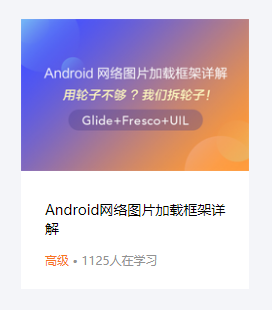


### 5.2 小米登录框（★★★）

`02-小米登录框★★★/小米登录框.html`：外框 `356×339`；logo 是 `49×49` 的透明 PNG，配橙色背景；标题、两个输入框和按钮依次用高度、外边距、内边距与 `box-sizing: border-box` 完成对齐。**源码中两个输入框都写成 `type="text"`，placeholder 也相同**，这里只记录原始静态布局，不擅自改成密码校验功能。

```html
<!DOCTYPE html>
<html lang="en">
<head>
	<meta charset="UTF-8">
	<meta name="viewport" content="width=device-width, initial-scale=1.0">
	<title>Document</title>
	<style>
		* {
			margin: 0;
			padding: 0;
		}

		.box {
			width: 356px;
			height: 339px;
			margin: 100px auto;
		}

		.box h1 {
			width: 49px;
			height: 49px;
			/* logo这个背景图片是透明的四周中间有白色的logo，所以需要设置背景颜色从而衬托出白色的logo */
			background: #ff4c00 url('./images/mi-logo.png');
			margin: 0 auto;
		}

		.box h2 {
			height: 77px;
			margin-top: 35px;
			text-align: center;
			font-size: 30px;
			font-weight: 400;
		}

		.box input {
			width: 356px;
			height: 50px;
			border: 1px solid #ccc;
			padding-left: 15px;
			margin-bottom: 14px;
			/* 不要盒子被撑大，自动内减 */
			box-sizing: border-box;
		}

		.box button {
			width: 356px;
			height: 50px;
			background-color: #ff4c00;
			color: #fff;
			border: none;
		}
	</style>
</head>
<body>
	<div class="box">
		<h1></h1>
		<h2>小米账号登录</h2>
		<input type="text" placeholder="邮箱/手机/小米ID">
		<input type="text" placeholder="邮箱/手机/小米ID">
		<button>登录</button>
	</div>
</body>
</html>
```

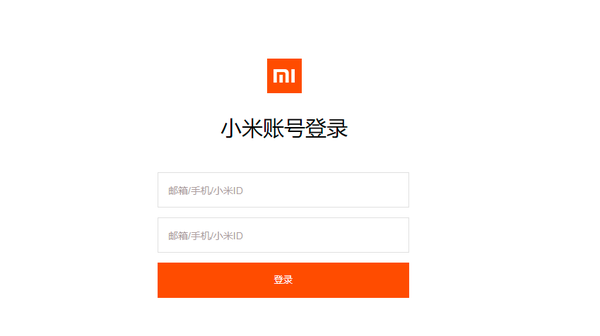

配套效果图同样显示两个相同占位提示。logo 需要用 `#ff4c00` 衬托透明图中的白色标识；输入框的356×50包含1px边框与15px左内边距，依靠 `border-box` 与同宽按钮对齐，两个输入框各有14px下外边距。观察这些位置与尺寸即可验证静态案例。


### 5.3 爱宠知识新闻列表（★★★★）

`03-爱宠知识新闻案例★★★★/爱宠知识案例.html`：外框 `262×342`，`1px` 绿色边框、`10px 10px 0` 内边距、`border-box` 和背景平铺图；标题用左边框和内边距，列表白底、去项目符号，每行有虚线底边和左侧小图标。

背景素材 `bg.gif` 为16×16，会默认平铺；项目图标 `tb.gif` 为12×12，使用 `no-repeat left center`，结合15px左内边距避开文字。标题左边框5px、左内边距10px、行高25px；列表行内容高30px，加1px底边框实际为31px，因为这里只给外框设置 `border-box`。对照9条完整文本、白色列表区域、左侧图标和虚线，检查结果。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <meta http-equiv="X-UA-Compatible" content="ie=edge">
  <title>Document</title>
  <style>
    
    /* 项目开始前需要去除标签默认的margin和padding */
    * {
      margin: 0;
      padding: 0;
    }

    .box {
      /* 1、宽度和高度 */
      width: 262px;
      height: 342px;
      /* 2、盒子模型的其他部分：border、padding、margin */
      border: 1px solid #009900;
      /* 自动内减 */
      padding: 10px 10px 0px;
      margin: 0 auto;
      margin-top: 100px;
      box-sizing:border-box;
      /* 3、写其他的样式：font、背景颜色、文字颜色 */
      background: url('./images/bg.gif');
    }


    .box h2 {
      /* background-color: pink; */
      /* 1、宽度和高度 */
      height: 25px;
      border-left: 5px solid #c9e143;
      padding-left: 10px;
      margin-bottom: 5px;
      font-size: 18px;
      line-height: 25px;
      color: #fff;
    }

    .box ul {
      list-style: none;
      background-color: #fff;
      padding: 0 10px;
    }

    .box ul li {
      height: 30px;
      border-bottom: 1px dashed #666666;
      padding-left: 15px;
      line-height: 30px;
      background: url('./images/tb.gif') no-repeat left center;
    }

    .box ul li a {
      text-decoration: none;
      font-size: 12px;
      color: #551a8b;
    }

  </style>
</head>
<body>
  <div class="box">
    <h2>爱宠知识</h2>
    <ul>
      <li><a href="#">养狗比养猫对健康更有利</a></li>
      <li><a href="#">日本正宗柴犬亮相，你怎么看柴犬</a></li>
      <li><a href="#">狗狗歌曲《新年旺旺》</a></li>
      <li><a href="#">带宠兜风，开车带宠需要注意什么？</a></li>
      <li><a href="#">【爆笑】这狗狗太不给力了</a></li>
      <li><a href="#">狗狗与男童相同着装拍有爱造型照</a></li>
      <li><a href="#">狗狗各个阶段健康大事件</a></li>
      <li><a href="#">调皮宠物狗陷在沙发里的搞笑瞬间</a></li>
      <li><a href="#">为什么每次大小便后，会用脚踢土？</a></li>
    </ul>
  </div>
</body>
</html>
```

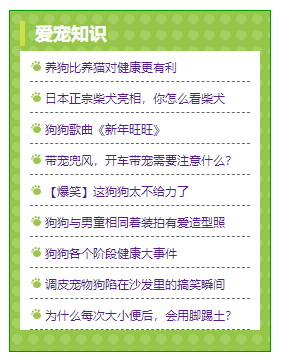

运行这三个选做案例时，保留各自目录下的 `images/product.png`、`images/mi-logo.png`、`images/bg.gif` 和 `images/tb.gif`。晚自习流程建议先复习 XMind，再把课堂代码重复敲熟，完成两个必做案例，最后按时间选择选做案例；这里不展开课程之外的学习任务。


## 6. 本日复习清单

- 能写出 `继承 < * < 标签 < 类 < ID < 行内 < !important`，并知道 `!important` 不能提升继承来源。
- 能按 `(行内, ID, 类, 标签)` 从左往右比较权重，理解不进位和层叠顺序。
- 能用 `Elements`、`Styles`、删除线和警告定位选择器、覆盖与语法错误。
- 能说出 `content / padding / border / margin` 四部分，并计算默认内容盒模型下的实际宽高。
- 能写出 `border: 1px solid red`、`padding: 20px 10px`、`box-sizing: border-box` 和 `margin: 0 auto`。
- 能区分水平外边距相加、垂直块级外边距合并、嵌套子元素 `margin-top` 塌陷，以及行内元素垂直边距的边界。
- 能按“从外往内、从上往下”完成新浪导航和网页新闻列表。
